# Train a Linear model, convert it to an MoE

**Assignment:** train a linear model, turn it into a Mixture-of-Experts, and show that training **continues** and **loss goes down**.

Small MLP on synthetic regression, CPU-friendly. Helpers live in `src/`.


Cloning into 'ERA'...
remote: Enumerating objects: 552, done.
remote: Counting objects: 100% (552/552), done.
remote: Compressing objects: 100% (412/412), done.
remote: Total 552 (delta 141), reused 523 (delta 123), pack-reused 0 (from 0)
Receiving objects: 100% (552/552), 6.10 MiB | 2.99 MiB/s, done.
Resolving deltas: 100% (141/141), done.


In [3]:
import os
import sys
from pathlib import Path

def find_project_root() -> Path | None:
    def ok(p: Path) -> bool:
        return (p / "src" / "__init__.py").is_file()
    for start in (Path.cwd(), Path("/content"), Path("/content/ERA/Assignment14")):
        try:
            cur = start.resolve()
        except OSError:
            continue
        for cand in [cur, *cur.parents]:
            if ok(cand):
                return cand
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError("src/ not found. Open this notebook from Assignment14/.")
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / "outputs" / ".mplconfig"))
print("root:", PROJECT_ROOT)


root: /content


In [4]:
from IPython.display import Image, display

from src.config import ExperimentConfig, get_runtime_info, resolve_device, set_seed
from src.data import make_synthetic_data
from src.dense_model import build_dense_model, count_parameters
from src.evaluate import compare_outputs, split_eval_bundle
from src.plotting import plot_dataset, plot_dense_vs_moe_losses, plot_loss_curves
from src.train import train_model
from src.upcycling import upcycle_dense_to_moe

cfg = ExperimentConfig(run_ablation=False, run_scratch_control=False)
set_seed(cfg.seed)
device = resolve_device(cfg.device)
print(get_runtime_info(device))
print("experts / top-k:", cfg.num_experts, "/", cfg.top_k)


{'python': '3.13.16', 'pytorch': '2.11.0+cu130', 'numpy': '2.1.3', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'device': 'cuda', 'cuda_available': True, 'cuda_device_name': 'Tesla T4'}
experts / top-k: 4 / 2


## Data


{'x_train': (1024, 8), 'y_train': (1024, 1), 'x_val': (256, 8), 'y_val': (256, 1), 'x_test': (256, 8), 'y_test': (256, 1)}


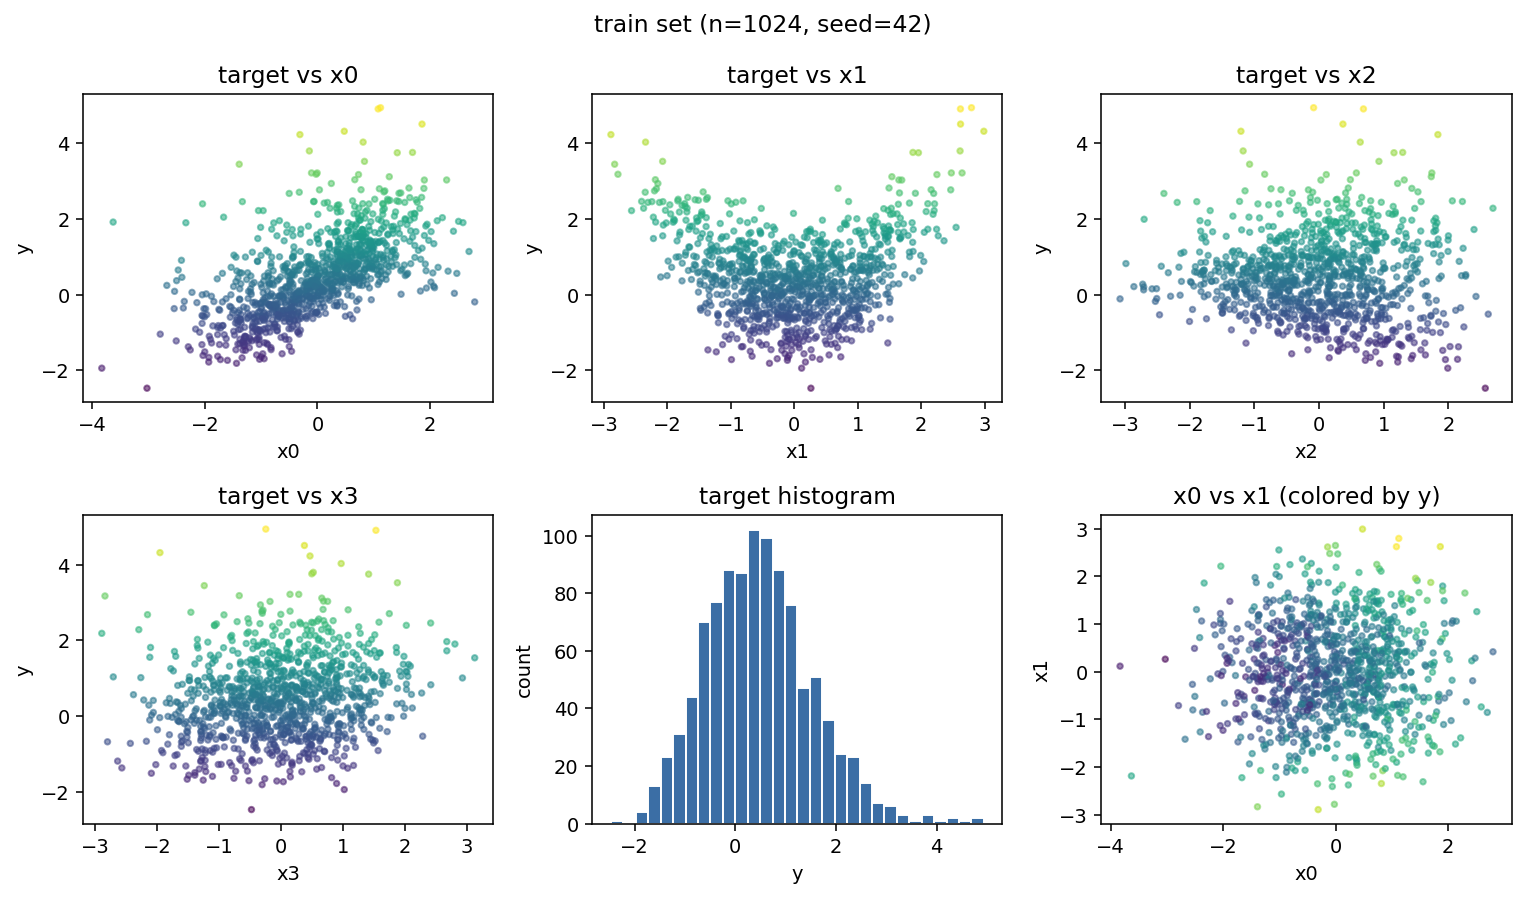

In [5]:
data = make_synthetic_data(cfg, seed=cfg.seed)
print(data.shapes())
display(Image(str(plot_dataset(
    data.x_train, data.y_train, "outputs/figures/dataset.png",
    title=f"train set (n={cfg.n_train}, seed={cfg.seed})",
))))


## 1. Train the dense linear model


params 2433 init train MSE 1.5322
dense 01  train=1.3850  val=1.4680
dense 02  train=1.0486  val=1.0834
dense 03  train=0.7423  val=0.7708
dense 04  train=0.5664  val=0.6069
dense 05  train=0.4656  val=0.5243
dense 06  train=0.4024  val=0.4601
dense 07  train=0.3466  val=0.3824
dense 08  train=0.2836  val=0.2997
dense 09  train=0.2177  val=0.2216
dense 10  train=0.1598  val=0.1482
dense 11  train=0.1201  val=0.1123
dense 12  train=0.0984  val=0.0948
dense 13  train=0.0910  val=0.0810
dense 14  train=0.0855  val=0.0805
dense 15  train=0.0798  val=0.0738
dense 16  train=0.0757  val=0.0697
dense 17  train=0.0719  val=0.0649
dense 18  train=0.0674  val=0.0655
dense 19  train=0.0640  val=0.0552
dense 20  train=0.0597  val=0.0536
dense 21  train=0.0566  val=0.0529
dense 22  train=0.0521  val=0.0453
dense 23  train=0.0481  val=0.0457
dense 24  train=0.0446  val=0.0408
dense 25  train=0.0412  val=0.0370
dense 26  train=0.0389  val=0.0346
dense 27  train=0.0350  val=0.0350
dense 28  train=0.032

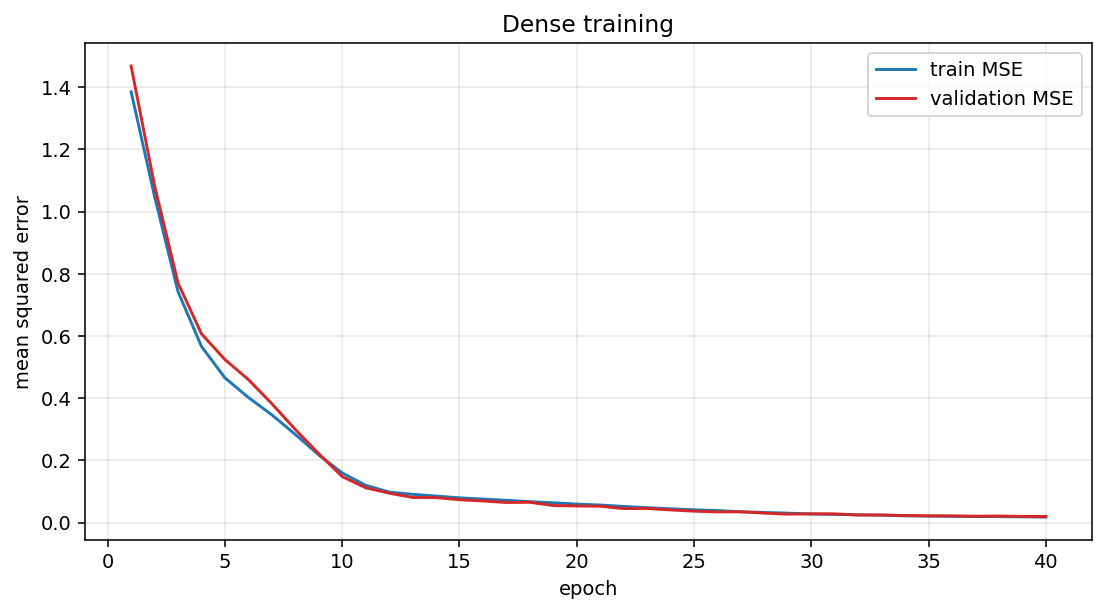

In [6]:
dense = build_dense_model(cfg).to(device)
before = split_eval_bundle(dense, data.train_loader, data.val_loader, data.test_loader, device)
print("params", count_parameters(dense), "init train MSE", round(before["train"]["train_mse"], 4))

dense_fit = train_model(
    dense, data.train_loader, data.val_loader, cfg, device,
    epochs=cfg.dense_epochs, learning_rate=cfg.learning_rate,
    checkpoint_path="outputs/checkpoints/dense_best.pt",
    log_fn=lambda r: print(f"dense {r['epoch']:02d}  train={r['train_mse']:.4f}  val={r['val_mse']:.4f}"),
)
after_dense = split_eval_bundle(dense, data.train_loader, data.val_loader, data.test_loader, device)
print("best epoch", dense_fit["best_epoch"], "val MSE", round(dense_fit["best_val_mse"], 4))
display(Image(str(plot_loss_curves(dense_fit["history"], "outputs/figures/dense_loss.png", "Dense training"))))


## 2. Convert the trained model into an MoE


In [8]:
moe, report = upcycle_dense_to_moe(dense, cfg, seed=cfg.seed)
moe = moe.to(device)
gap = compare_outputs(dense, moe, data.x_val, device)
start = split_eval_bundle(moe, data.train_loader, data.val_loader, data.test_loader, device)
print("copied exactly:", report.all_copied_exactly, "| dense unchanged:", report.dense_unchanged)
print("MoE vs dense max |dely| before fine-tune:", f"{gap['max_abs_diff']:.2e}")
print("MoE train MSE at conversion:", round(start["train"]["train_mse"], 6))


copied exactly: True | dense unchanged: True
MoE vs dense max |dely| before fine-tune: 7.15e-07
MoE train MSE at conversion: 0.016999


## 3. Keep training the MoE — loss should drop


moe   01  train=0.0201  val=0.0210
moe   02  train=0.0169  val=0.0212
moe   03  train=0.0168  val=0.0200
moe   04  train=0.0164  val=0.0183
moe   05  train=0.0144  val=0.0177
moe   06  train=0.0143  val=0.0197
moe   07  train=0.0131  val=0.0189
moe   08  train=0.0131  val=0.0169
moe   09  train=0.0122  val=0.0181
moe   10  train=0.0111  val=0.0163
moe   11  train=0.0110  val=0.0177
moe   12  train=0.0110  val=0.0163
moe   13  train=0.0107  val=0.0176
moe   14  train=0.0107  val=0.0151
moe   15  train=0.0097  val=0.0156
moe   16  train=0.0092  val=0.0159
moe   17  train=0.0100  val=0.0148
moe   18  train=0.0090  val=0.0148
moe   19  train=0.0088  val=0.0130
moe   20  train=0.0085  val=0.0134
moe   21  train=0.0089  val=0.0137
moe   22  train=0.0084  val=0.0130
moe   23  train=0.0081  val=0.0136
moe   24  train=0.0077  val=0.0122
moe   25  train=0.0077  val=0.0125
moe   26  train=0.0075  val=0.0130
moe   27  train=0.0075  val=0.0137
moe   28  train=0.0075  val=0.0132
moe   29  train=0.00

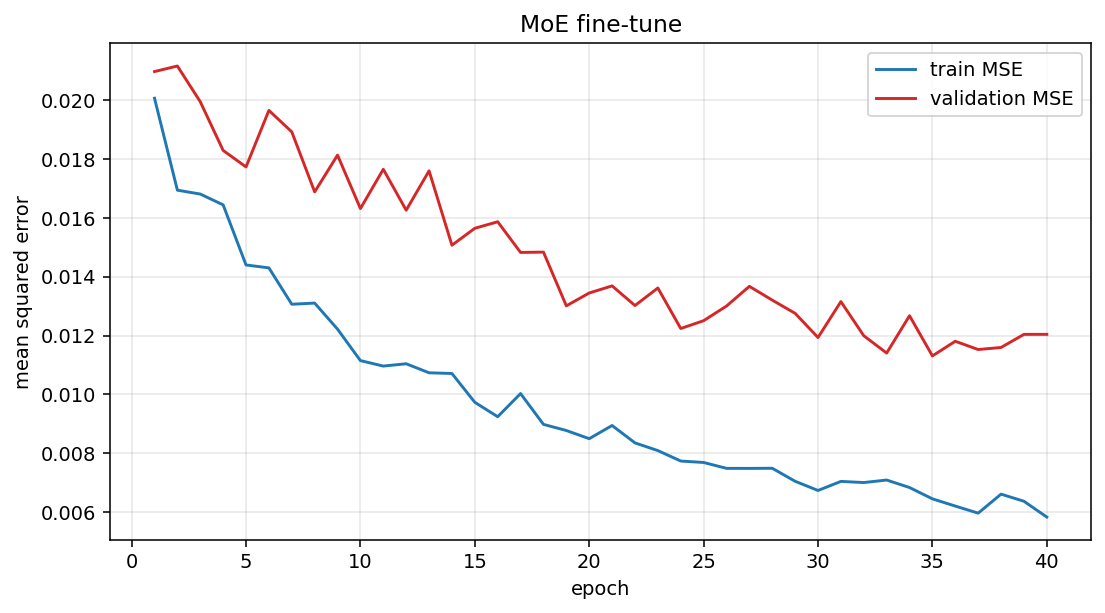

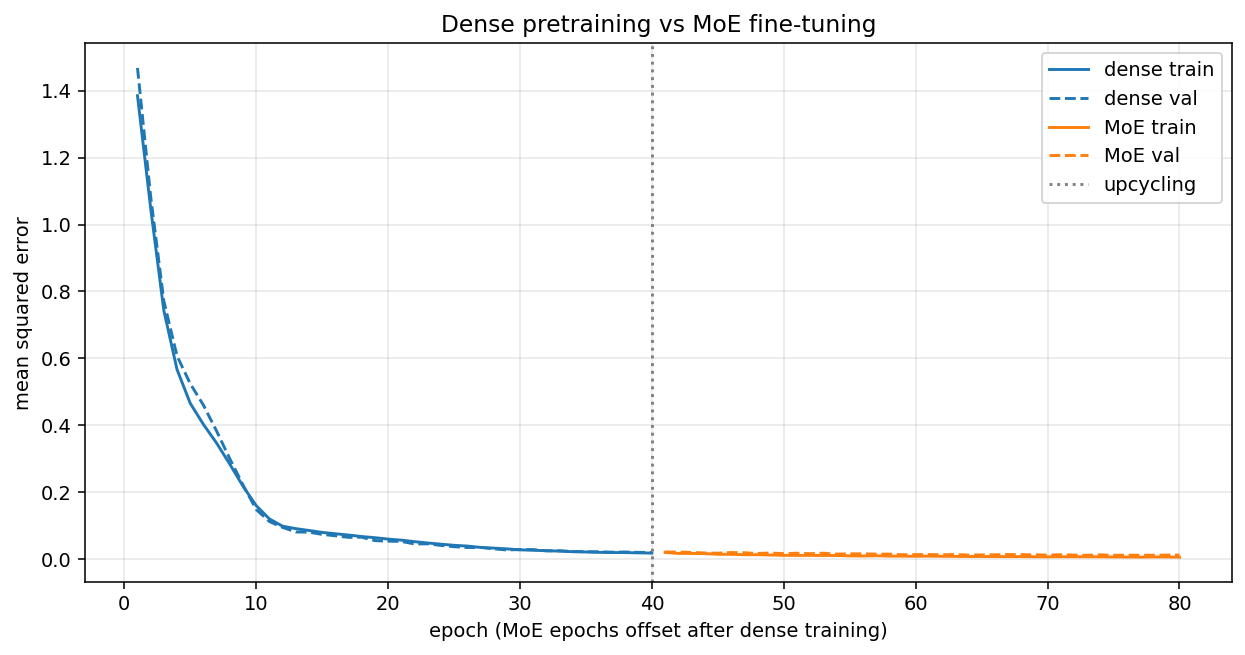

In [9]:
moe_fit = train_model(
    moe, data.train_loader, data.val_loader, cfg, device,
    epochs=cfg.moe_epochs, learning_rate=cfg.moe_learning_rate,
    checkpoint_path="outputs/checkpoints/moe_best.pt",
    log_fn=lambda r: print(f"moe   {r['epoch']:02d}  train={r['train_mse']:.4f}  val={r['val_mse']:.4f}"),
)
after_moe = split_eval_bundle(moe, data.train_loader, data.val_loader, data.test_loader, device)
start_mse = start["train"]["train_mse"]
end_mse = moe_fit["history"][-1]["train_mse"]
ok = end_mse < start_mse - 1e-4
print(f"MoE train MSE {start_mse:.6f} → {end_mse:.6f}   continued and reduced? {ok}")
print("dense test MSE", round(after_dense["test"]["test_mse"], 4), "| MoE test MSE", round(after_moe["test"]["test_mse"], 4))
display(Image(str(plot_loss_curves(moe_fit["history"], "outputs/figures/moe_loss.png", "MoE fine-tune"))))
display(Image(str(plot_dense_vs_moe_losses(
    dense_fit["history"], moe_fit["history"],
    "outputs/figures/dense_vs_moe_loss.png",
    moe_epoch_offset=cfg.dense_epochs,
))))
